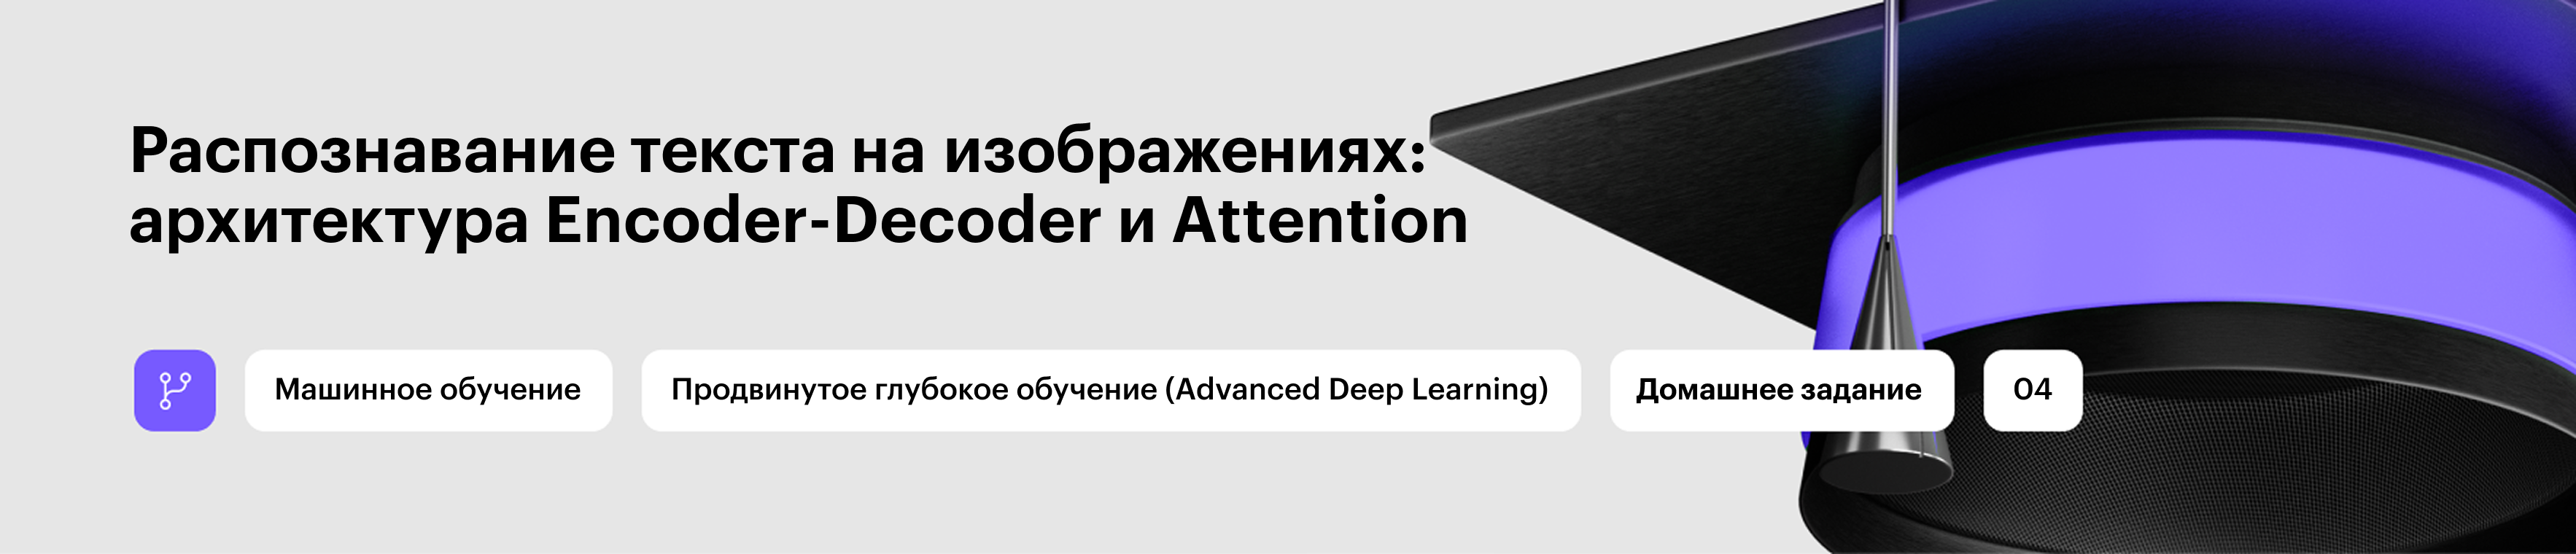

## Домашнее задание 4. Распознавание текста на изображениях. Часть 2

<img src="...
" alt="drawing" width="1000"/>


# О формате сдачи

🔷 **<font color='plum'>При решении ноутбука используй данный шаблон.</font>**

    ✅ Можно добавлять новые ячейки любых типов.
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий.


🔷 **<font color='plum'>При оценивании задач учитывается код.</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами «Your code here» / «Твой код» и аналогичными.
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов.
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно.

🔷 **<font color='plum'>При оценивании задач учитываются выводы.</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами «Вывод» / «Ответ на вопрос» / «Твой текст» и аналогичными.
    ✅ Обычно выводы подразумевают под собой текстовый ответ (можно писать Markdown, LaTeX).
    ✅ Сопутствующие изображения, графики, таблички приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл.

----
## <font color='OrangeRed'>**Внимание! Аларм! Ахтунг!**</font>

* Данный ноутбук желательно выполнять на внутренней платформе <font color='DarkSeaGreen'>**jupyter.culab**</font> ЦУ.

* Работоспособность данного ноутбука проверена именно на <font color='DarkSeaGreen'>**jupyter.culab**</font>, работоспособность «из-под коробки» на других платформах мы не гарантируем.

* Ты можешь делать задание у себя локально / Google Colab / Kaggle и пр. при желании, однако работать с дополнительными файлами и настраивать окружение придётся самостоятельно.

* Подробнее об использовании внутренней платформы читай в описании курса.

### <font color='DarkOrange'> **Основная часть [10 баллов]** </font>

---

- Набор данных:

    состоит из 10327 `простых` изображений и 14222 `сложных` изображений, имя файла содержит информацию о тексте регистрационного знака (пример: `rus_14716_X222PP150.png`, ..., `rus_14732_Y940KC197.png`).
      
- Задача:

    требуется разработать модель, которая будет решать задачу распознавания текста на изображении.
  
- Модель <font color='DarkOrange'> **[2 баллa]** </font>

    Используй наработки с прошлого домашнего задания и семинара по CRNN. Модель должна следовать основным принципам, продемонстрированным на семинаре.

    <font color='LightSteelBlue'>**Пояснение:**</font> можно разработать гибридную модель, которая состоит из основной модели (`Encoder-Decoder`) и дополнительной модели (`SpatialTransformer`).

    <font color='LightSteelBlue'>**Пояснение:**</font> можно попробовать разнообразные бэкбоны (например `ResNet`, `GoogleNet`, `MobileNet` ).

- Результат <font color='DarkOrange'> **[8 баллов]** </font>

    * Разбей выборку изображений `сложных` и `простых` регистрационных знаков случайным образом на тренировочную и валидационную в соотношении `0,7` и `0,3`.

    * Натренируй разработанную тобой модель (обучение на требуемое качество займёт не очень много времени, в пределах 10–60 минут, в зависимости от сложности реализации модели).
    
    * Метрикой в домашней работе является расстояние Левенштейна. Твоё решение должно обеспечить метрику менее `0,15` на валидационной выборке. Используй библиотеку
    (https://github.com/rapidfuzz/RapidFuzz), код метрики приведён ниже.

---

## <font color='MediumSeaGreen'> **Бонус [3 балла]** </font>

Объедини результаты прошлой домашней работы (детекцию номеров) с текущими результатами. Продемонстрируй на выбранных тобой изображениях решение задачи детектирования регистрационных знаков и их распознавание.

<font color='LightSteelBlue'>**Пояснение:**</font> приведи полный пайплайн (можно объединять код, написанный в предыдущих ДЗ, с текущим). Код для обучения должен присутствовать. При необходимости натренируй модель детекции из прошлого домашнего задания.

---

### Набор данных

In [ ]:
!mkdir -p data
!curl -O https://files.culab.ru/files/public/DeepLearningAdvanced/seminars/license-plate-recognition.zip
!unzip -o license-plate-recognition.zip -d data >/dev/null
!rm license-plate-recognition.zip

In [ ]:
! pip install rapidfuzz plotly

In [ ]:
import plotly.subplots as sp
import plotly.express as px
from rapidfuzz.distance import Levenshtein

import random
import os

from PIL import Image

def load_random_images_from_dir(directory, num_images=5):
    # Get a list of all files in the directory
    all_files = os.listdir(directory)
    # Filter out files that are not images (assuming common image formats)
    image_files = [f for f in all_files if f.lower().endswith(('.png', '.jpg', '.jpeg', '.gif', '.bmp'))]
    # Randomly select the specified number of images
    selected_files = random.sample(image_files, num_images)
    return [os.path.join(directory, f) for f in selected_files]

def create_image_subplot(image_paths):
    # Create a subplot for the images
    fig = sp.make_subplots(rows=len(image_paths), cols=1, subplot_titles=[os.path.basename(p) for p in image_paths])

    for i, image_path in enumerate(image_paths):
        img = Image.open(image_path)
        fig.add_trace(
            px.imshow(img).data[0],
            row=i+1, col=1
        )

    # Update layout to make sure images are displayed correctly
    fig.update_layout(height=400, width=200*len(image_paths), showlegend=False)
    fig.update_layout(showlegend=False)
    fig.update_xaxes(visible=False)
    fig.update_yaxes(visible=False)
    fig.show()


def mean_levenshtein_distance(lft_set, rht_set):
    # Функция подсчёта метрики
    total_distance, total_size = 0, min( len(lft_set), len(rht_set) )
    for lft_item, rht_item in zip(lft_set, rht_set):
        print(lft_item, rht_item)
        total_distance += Levenshtein.distance(lft_item, rht_item)
    return total_distance / total_size

# Example usage:
prediction_s = ["hello", "world", "example"]
true_s       = ["world", "example", "hello"]

distance = mean_levenshtein_distance(prediction_s, true_s)
print(f"The total Levenshtein distance between the sets is: {distance}")


# Directory containing images
directory = 'data/train/train/complex/'

# Load five random images from the directory
image_paths = load_random_images_from_dir(directory, num_images=5)

# Create and display the subplot with the images
create_image_subplot(image_paths)